# Filtragem convolucional

Nesta lição, vamos exercitar os filtros lineares usando convolução.

A ideia é que você modifique estes exemplos para rodar com as suas imagens. Experimente outros kernels.


In [58]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, color, img_as_float
from skimage.util import img_as_ubyte
from skimage.filters import prewitt_h, prewitt_v, roberts
from scipy.signal import convolve2d

def normalize01(x):
    x = x.astype(np.float64)
    x = x - x.min()
    if x.max() > 0:
        x = x / x.max()
    return x

def grad_magnitude(gx, gy):
    return np.sqrt(gx**2 + gy**2)

def show_images(imgs, titles=None, cmap=None, figsize=(14, 6)):
    """Utility to visualize one row of images."""
    n = len(imgs)
    if titles is None:
        titles = ["" for _ in range(n)]
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(imgs, titles), start=1):
        plt.subplot(1, n, i)
        if im.ndim == 2:
            plt.imshow(im, cmap=cmap if cmap else 'gray')
        else:
            plt.imshow(im)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

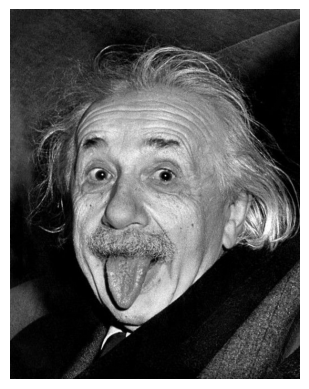

In [59]:
from skimage import data
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

camera = Image.open('/content/AlbertEinstein.jpg')
camera = np.array(camera)
camera = color.rgb2gray(camera)

plt.imshow(camera, cmap='gray')
plt.axis('off')
plt.show()

## Convolução

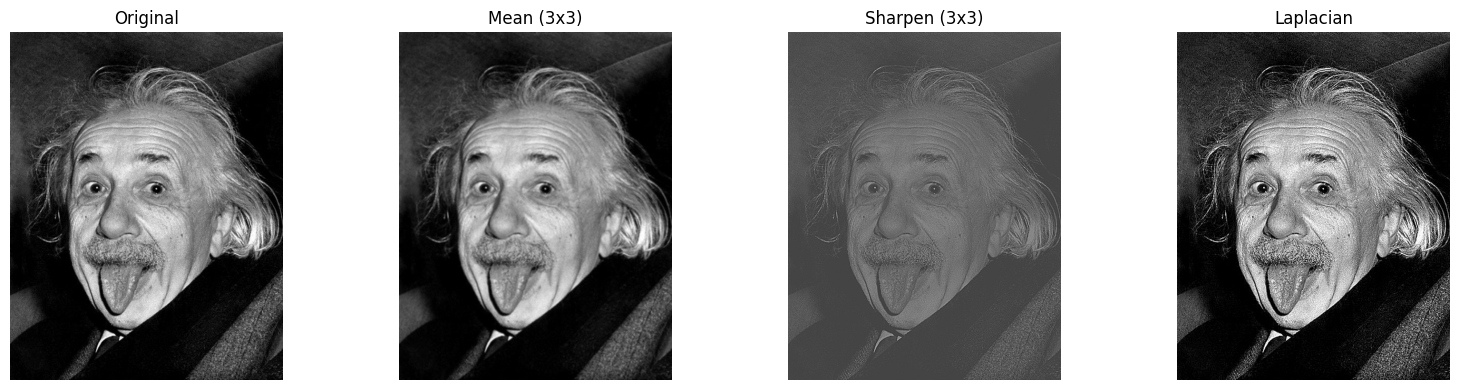

In [60]:
# Vamos pegar alguns kernels da aula
meanK3x3 = np.ones((3, 3), dtype=np.float64) / 9.0

sharpenK3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]], dtype=np.float64)

laplacianK3x3 = np.array([[ 0,  1,  0],
                         [ 1, -4,  1],
                         [ 0,  1,  0]], dtype=np.float64)

def convolveImage(img, kernel, boundary='symm'):
    """Convolucao 2D de uma imagem em nivel de cinza."""
    res = convolve2d(img, kernel, mode='same', boundary=boundary)
    return res

resMedia = convolveImage(camera, meanK3x3)

resSharpened = convolveImage(camera, sharpenK3x3)

resLaplacian = convolveImage(camera, laplacianK3x3)
resLaplacian = np.clip(camera - 0.7 * resLaplacian, 0, 1)


show_images(
    [camera, resMedia, resSharpened, resLaplacian],
    titles=["Original", "Mean (3x3)", "Sharpen (3x3)", "Laplacian"],
    cmap='gray',
    figsize=(16, 4)
)


### Convolução com loops

Igual ao slide da aula

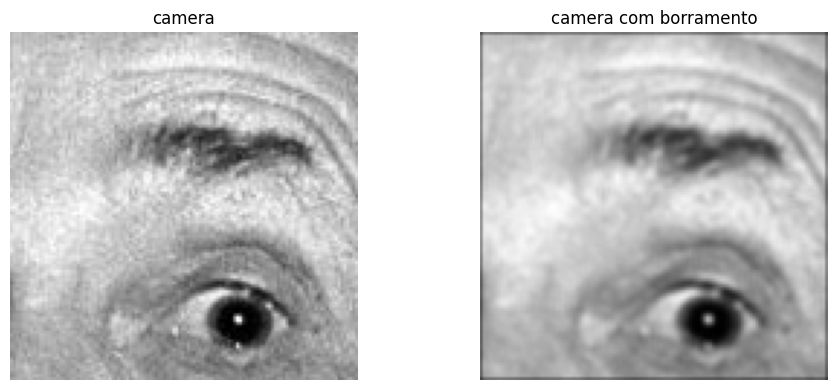

In [61]:
def conv2dWLoop(img, kernel):
    """Convolucao com (zero padding). O kernel precisa ter lados ímpares."""
    # Mudando os tipos para usar numpy
    img = img.astype(np.float64)
    k = kernel.astype(np.float64)
    # Tomando as dimensoes e verificando se o kernel tem as dimensoes corretas
    kh, kw = k.shape
    assert (kh % 2 == 1) and (kw % 2 == 1)
    # zero-padding
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    outImage = np.zeros_like(img, dtype=np.float64)
    # espelhando o kernel para fazer uma convolucao de verdade
    kernelV = np.flipud(np.fliplr(k))
    H, W = img.shape
    for i in range(H):
        for j in range(W):
            patch = padded[i:i+kh, j:j+kw]
            outImage[i, j] = np.sum(patch * kernelV)
    return outImage

cameraSmall = camera[200:320, 200:320]
resMeanCamera = conv2dWLoop(cameraSmall, meanK3x3)

show_images(
    [cameraSmall, resMeanCamera],
    titles=["camera", "camera com borramento"],
    cmap='gray',
    figsize=(10, 4)
)


## Prewitt (realce de bordas)

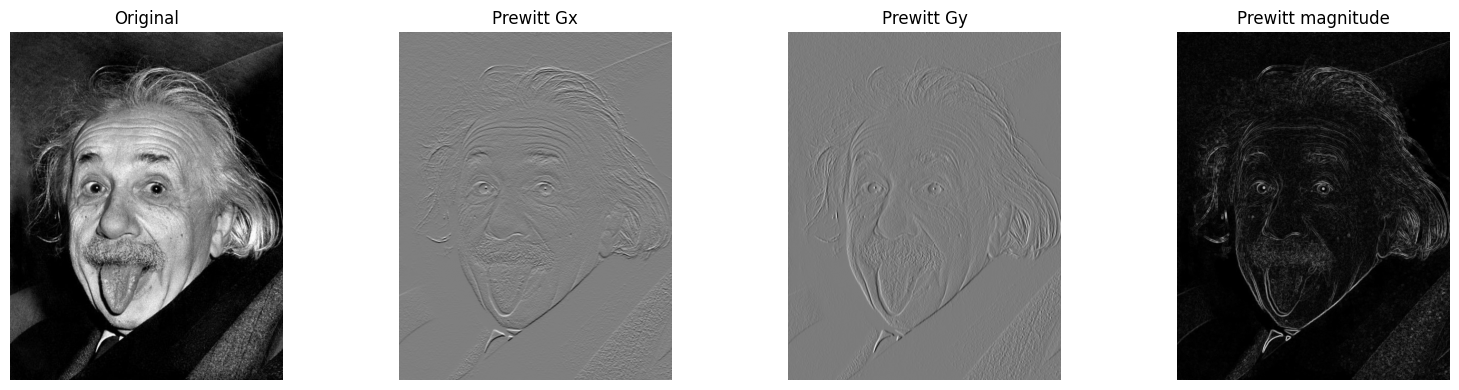

In [62]:
gx = prewitt_h(camera)
gy = prewitt_v(camera)
mag = grad_magnitude(gx, gy)

show_images(
    [camera, gx, gy, normalize01(mag)],
    titles=["Original", "Prewitt Gx", "Prewitt Gy", "Prewitt magnitude"],
    cmap='gray',
    figsize=(16, 4)
)


## Roberts (realce de bordas)

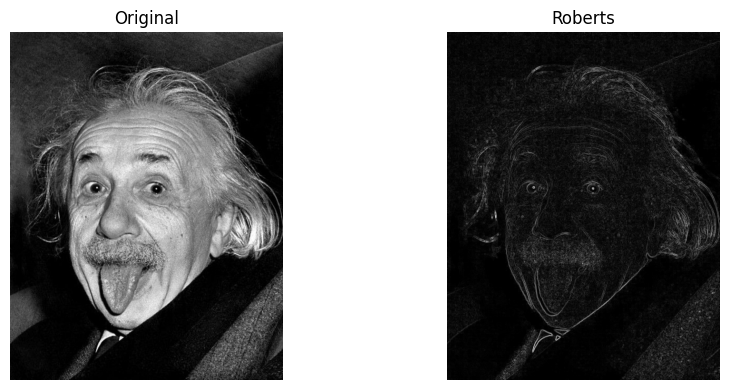

In [63]:
resRoberts = roberts(camera)

show_images(
    [camera, normalize01(resRoberts)],
    titles=["Original", "Roberts"],
    cmap='gray',
    figsize=(10, 4)
)


## Exercícios extras

1. **Convolução**
   - Experimente um filtro da média com kernel 5×5 e compare com o 3×3.
   - Experimente o filtro Gaussiano com a função `skimage.filters.gaussian` e compare.

2. **Prewitt/Roberts**
   - Aplique os filtros de Prewitt e Roberts e, depois, faça aplique um threshold para conseguir as bordas binarizadas.
   - Adicione ruído e compare a robustez.

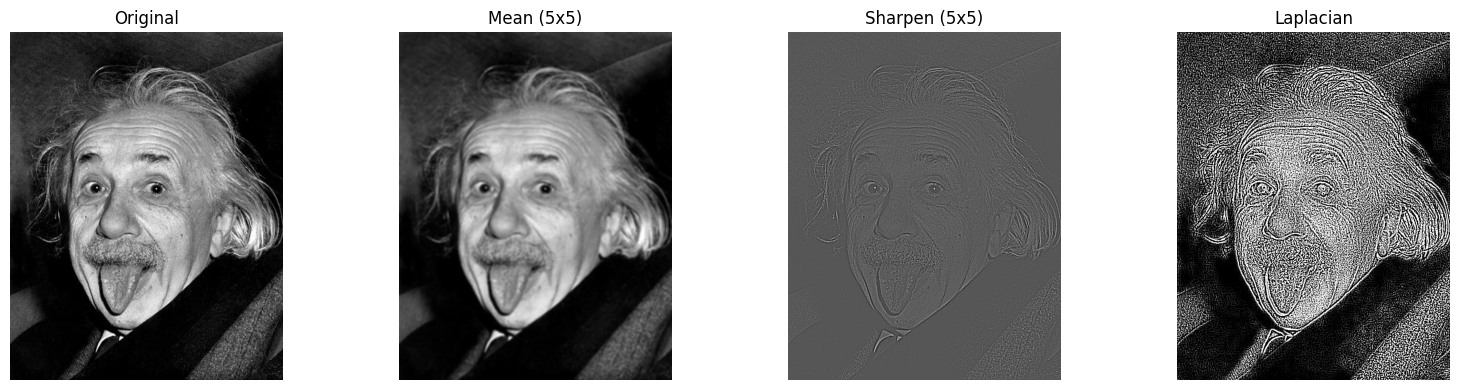

In [64]:
meanK5x5 = np.ones((5, 5), dtype=np.float64) / 25.0

sharpenK5x5 = np.array([[-1, -1, -1, -1, -1],
                       [-1, -1, -1, -1, -1],
                       [-1, -1, 25, -1, -1],
                       [-1, -1, -1, -1, -1],
                       [-1, -1, -1, -1, -1]], dtype=np.float64)

laplacianK5x5 = np.array([[-1, -1, -1, -1, -1],
                         [-1, -1, -1, -1, -1],
                         [-1, -1, 24, -1, -1],
                         [-1, -1, -1, -1, -1],
                         [-1, -1, -1, -1, -1]], dtype=np.float64)

resMedia = convolveImage(camera, meanK5x5)

resSharpened = convolveImage(camera, sharpenK5x5)

resLaplacian = convolveImage(camera, laplacianK5x5)
resLaplacian = np.clip(camera - 0.7 * resLaplacian, 0, 1)


show_images(
    [camera, resMedia, resSharpened, resLaplacian],
    titles=["Original", "Mean (5x5)", "Sharpen (5x5)", "Laplacian"],
    cmap='gray',
    figsize=(16, 4)
)

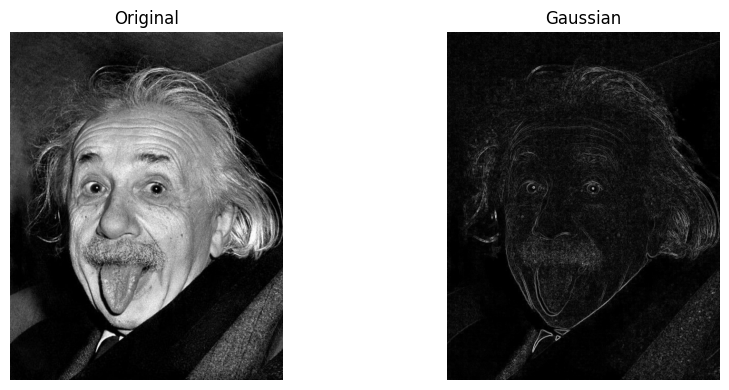

In [65]:
import skimage.filters as filters

show_images(
    [camera, normalize01(resRoberts)],
    titles=["Original", "Gaussian"],
    cmap='gray',
    figsize=(10, 4)
)

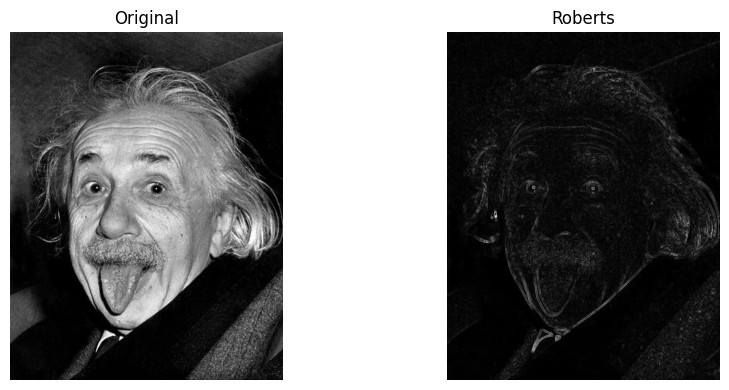

In [66]:
prewitt_roberts = filters.roberts(mag)

show_images(
    [camera, normalize01(prewitt_roberts)],
    titles=["Original", "Roberts"],
    cmap='gray',
    figsize=(10, 4)
)

## O filtro Gaussian deu uma maior gama de detalhes qeu os demais nas bordas claras da imagem